# 10. SVM Classifier

**Project** · Student Exam Result Prediction  
**Problem type** · Classification

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

An SVM separates classes by placing a decision boundary with room on either side. A kernel can supply a curved boundary when attendance interacts with scores. Support vectors are training rows that contribute to the fitted decision function.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

A weighted combination of marks and assignments, an attendance adjustment and a 19-point penalty below 62% attendance creates a latent grade. Gaussian noise of eight points is added. Grades at least 57 receive Pass. Assignment and internal scores are partially correlated.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `attendance_pct` | decimal | percent | Course sessions attended |
| `internal_marks` | decimal | points out of 100 | Internal assessment result |
| `assignment_score` | decimal | points out of 100 | Coursework score |
| `exam_result` | string | Fail, Pass | Observed class label |

**Independent variables (X)** · `attendance_pct`, `internal_marks`, `assignment_score`.

**Dependent variable (y)** · `exam_result` is the class to predict. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "10_exam_results.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 4)


,attendance_pct,internal_marks,assignment_score,exam_result
0,55.8,100.0,65.0,Pass
1,79.5,62.2,61.3,Pass
2,88.8,76.5,42.6,Pass
3,98.2,37.7,40.9,Fail
4,71.7,75.3,89.8,Pass
5,78.0,51.7,91.2,Pass
6,58.6,94.5,68.9,Pass
7,95.2,26.7,26.0,Fail
8,63.7,87.2,49.8,Pass
9,70.2,95.3,86.9,Pass


attendance_pct      float64
internal_marks      float64
assignment_score    float64
exam_result             str
dtype: object

## 3. Mathematical Understanding

For a linear SVM the score is $f(x)=w\cdot x+b$, where $x$ is the feature vector, $w$ is the normal vector and $b$ an intercept. The hyperplane is $f(x)=0$, and the two canonical margin planes are $f(x)=\pm1$. Their distance is $2/\lVert w\rVert$. With labels $y_i\in\{-1,+1\}$ and training scores $f(x_i)$, a soft-margin fit trades small $\lVert w\rVert^2/2$ against $C\sum_i\max(0,1-y_i f(x_i))$. The sum is hinge loss and $C$ weights violations.

If $f(x)=2x_1+x_2-3$, then $(1,0)$ gives $-1$ and predicts Fail, while $(2,1)$ gives $2$ and predicts Pass. The margin width is $2/\sqrt5$. An RBF kernel uses $K(u,v)=e^{-\gamma\lVert u-v\rVert^2}$ for feature rows $u,v$ and locality parameter $\gamma$. It computes similarity in an implicit feature space without constructing those coordinates explicitly.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/svm.html)

## 4. Working Principle

Scale the inputs, learn a decision score from the margin objective, and classify by its sign. With the RBF kernel, nearby examples can exert local influence and the boundary can curve. The contour plot fixes assignment score so the three-variable decision surface can be read in two dimensions.

| Input | Decision score | Prediction |
| --- | --- | --- |
| (1, 0) | −1 | Fail |
| (2, 1) | 2 | Pass |

**Workflow diagram**

`Raw input` → `Standardized numeric values and any category indicators` → `Learns a maximum-margin boundary, optionally through a kernel` → `Class prediction`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows class balance. Feature plots show variation. Pearson correlation measures linear association. The category target is excluded. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "exam_result"
FEATURES = ["attendance_pct","internal_marks","assignment_score"]
NUMERIC = ["attendance_pct","internal_marks","assignment_score"]
CATEGORICAL = []
SEED = 42
LABELS = ["Fail","Pass"]

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   attendance_pct    1500 non-null   float64
 1   internal_marks    1500 non-null   float64
 2   assignment_score  1470 non-null   float64
 3   exam_result       1500 non-null   str    
dtypes: float64(3), str(1)
memory usage: 52.9 KB


,attendance_pct,internal_marks,assignment_score,exam_result
0,55.8,100.0,65.0,Pass
1,79.5,62.2,61.3,Pass
2,88.8,76.5,42.6,Pass
3,98.2,37.7,40.9,Fail
4,71.7,75.3,89.8,Pass


,attendance_pct,internal_marks,assignment_score,exam_result
1495,69.8,61.8,54.3,Pass
1496,94.0,40.9,48.2,Fail
1497,93.9,65.0,43.8,Pass
1498,92.0,96.0,73.0,Pass
1499,74.2,79.1,69.1,Pass


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
attendance_pct,1500.0,NaN,NaN,NaN,68.8926,18.06849,37.0,53.275,69.25,84.3,99.8
internal_marks,1500.0,NaN,NaN,NaN,59.456467,23.128707,20.0,39.15,59.6,79.025,100.0
assignment_score,1470.0,NaN,NaN,NaN,63.683946,19.48224,21.2,47.425,64.3,80.1,100.0
exam_result,1500,2,Fail,806,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing,Missing %
attendance_pct,0,0.0
internal_marks,0,0.0
assignment_score,30,2.0
exam_result,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

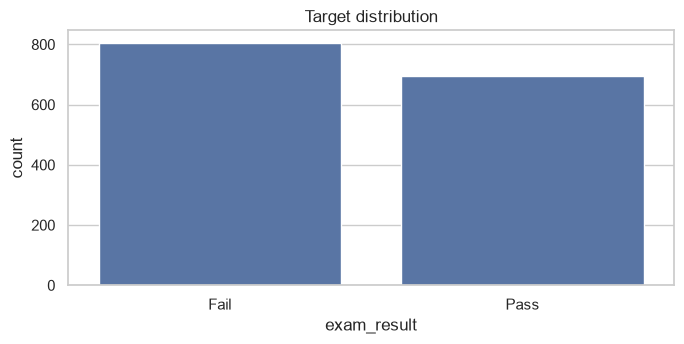

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.countplot(data=df, x=TARGET, order=LABELS, ax=ax)
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

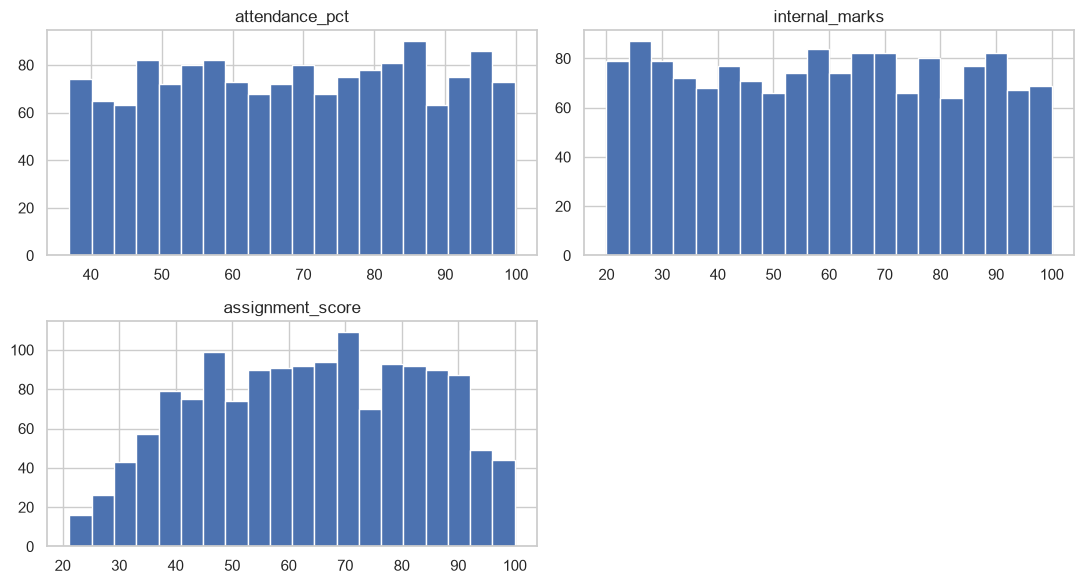

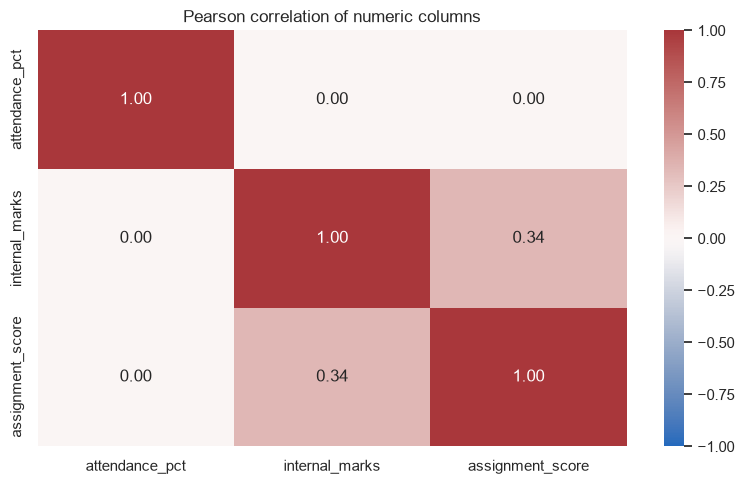

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. Stratification preserves approximate class proportions. The numeric branch fills blanks using training medians. This dataset has no categorical predictors. StandardScaler uses training means and standard deviations to make numeric magnitudes comparable. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
label_codes = {'Fail': 0, 'Pass': 1}
y = df[TARGET].map(label_codes)

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fill blank numbers, then put numeric columns on comparable scales.
numeric_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`C` controls the penalty for margin violations. `kernel` chooses linear or nonlinear similarity, and RBF `gamma` controls locality. SVC yields decision scores. The prediction exercise wraps the selected pipeline in `CalibratedClassifierCV` using training folds to estimate class probabilities. Its labels follow the calibrated estimates and can differ from raw SVC labels.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from sklearn.svm import SVC

estimator = SVC(C=2.0, kernel="rbf", gamma="scale", random_state=SEED)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['attendance_pct','internal_marks','assignment_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{tra

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print("Example predicted class:", LABELS[predictions[0]])

,attendance_pct,internal_marks,assignment_score
448,81.7,68.1,44.1


Example predicted class: Pass


## 8. Model Evaluation

Let $TP$ count correctly predicted positives, $TN$ correctly predicted negatives, $FP$ false positives, $FN$ false negatives and $N$ all test rows. Higher values indicate better scores, subject to the baseline and the costs of different errors.

| Measure | Formula and interpretation |
| --- | --- |
| Accuracy | $(TP+TN)/N$ for binary outcomes, or the proportion of correct predictions for multiple classes. |
| Precision | $TP/(TP+FP)$. Of the predicted positives, how many really were positive? |
| Recall | $TP/(TP+FN)$. Of the actual positives, how many did the model catch? |
| F1 | $2PR/(P+R)$ for precision $P$ and recall $R$. It is their harmonic mean. |
| ROC-AUC | Area $\int_0^1 \mathrm{TPR}\,d(\mathrm{FPR})$, with $\mathrm{TPR}=TP/(TP+FN)$ and $\mathrm{FPR}=FP/(FP+TN)$. Binary AUC measures the chance of ranking a random positive above a random negative, counting ties as half. Around 0.5 corresponds to chance ranking. |
| Confusion matrix | Entry $(i,j)$ counts rows with actual class $i$ and predicted class $j$. A strong diagonal indicates correct classifications. Examine the off-diagonal cells for costly errors. |
| Classification report | Applies precision, recall and F1 per class. Support counts actual examples per class. Macro averaging weights classes equally, and weighted averaging uses support. |

The positive class is **Pass**. ROC-AUC ranks by the decision score. A prior-only classifier gives a baseline. A class with no positive predictions gets zero precision by convention.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

AVERAGE = "binary"
CLASS_IDS = np.arange(len(LABELS))

test_scores = model.decision_function(X_test)

initial_metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

Accuracy     0.877
Precision    0.870
Recall       0.863
F1           0.866
ROC-AUC      0.945
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline knows the training class frequencies and sees no input features.
baseline = DummyClassifier(strategy="prior")
baseline_train = np.zeros((len(y_train), 1))
baseline_test = np.zeros((len(y_test), 1))
baseline.fit(baseline_train, y_train)

baseline_predictions = baseline.predict(baseline_test)
baseline_scores = baseline.predict_proba(baseline_test)[:, 1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_scores),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.537,0.00,0.000,0.000,0.500
Model,0.877,0.87,0.863,0.866,0.945


### Read the results for each class

In [14]:
print(classification_report(
    y_test, predictions, labels=CLASS_IDS, target_names=LABELS, zero_division=0
))

              precision    recall  f1-score   support

        Fail       0.88      0.89      0.89       161
        Pass       0.87      0.86      0.87       139

    accuracy                           0.88       300
   macro avg       0.88      0.88      0.88       300
weighted avg       0.88      0.88      0.88       300



## 9. Visualizations

Read the confusion matrix by row for each actual class. Off-diagonal cells show the direction and size of confusions. The ROC curve shows the recall and false-positive trade-off across score thresholds.

The zero contour is the RBF class boundary on a slice with assignment score fixed to the training median. The dashed contours show scores of −1 and +1. Marked support vectors are projected onto the slice from roughly comparable assignment scores. Their exact decision scores also depend on their original assignment values.

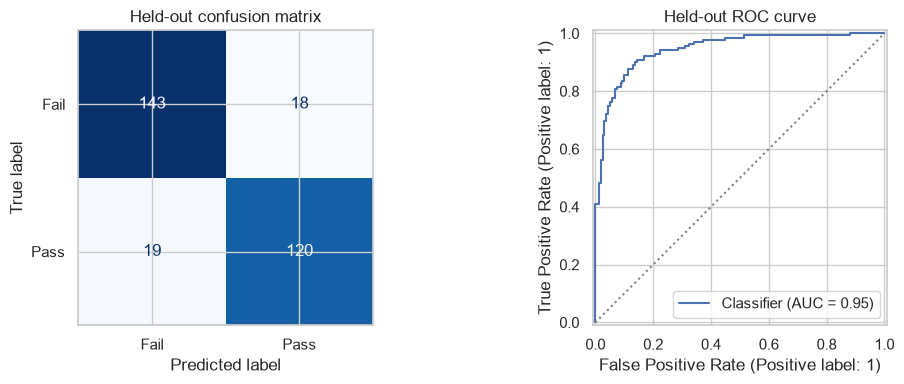

In [15]:
fig, (ax, roc_ax) = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=CLASS_IDS, display_labels=LABELS,
                                        colorbar=False, cmap="Blues", ax=ax)
ax.set_title("Held-out confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_scores, pos_label=1, ax=roc_ax)
roc_ax.plot([0, 1], [0, 1], linestyle=":", color="grey")
roc_ax.set_title("Held-out ROC curve")
fig.tight_layout()
plt.show()

### A closer look at this model

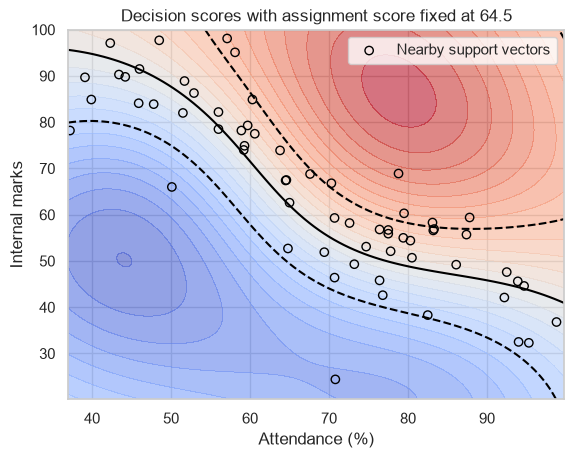

In [16]:
attendance = np.linspace(X_train["attendance_pct"].min(), X_train["attendance_pct"].max(), 100)
marks = np.linspace(X_train["internal_marks"].min(), X_train["internal_marks"].max(), 100)
attendance_grid, marks_grid = np.meshgrid(attendance, marks)
fixed_assignment = X_train["assignment_score"].median()
slice_grid = pd.DataFrame({
    "attendance_pct": attendance_grid.ravel(), "internal_marks": marks_grid.ravel(),
    "assignment_score": fixed_assignment,
})
scores = model.decision_function(slice_grid).reshape(attendance_grid.shape)
fig, ax = plt.subplots()
ax.contourf(attendance_grid, marks_grid, scores, levels=25, cmap="coolwarm", alpha=0.6)
ax.contour(attendance_grid, marks_grid, scores, levels=[-1, 0, 1], colors="black",
           linestyles=["dashed", "solid", "dashed"])
support = X_train.iloc[model.named_steps["model"].support_]
near_slice = support.loc[support["assignment_score"].sub(fixed_assignment).abs() <= 5]
ax.scatter(near_slice["attendance_pct"], near_slice["internal_marks"], facecolors="none",
           edgecolors="black", label="Nearby support vectors")
ax.set(xlabel="Attendance (%)", ylabel="Internal marks", title=f"Decision scores with assignment score fixed at {fixed_assignment:.1f}")
ax.legend()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled stratified folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by positive-class F1. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`C` controls the penalty for margin violations. `kernel` chooses linear or nonlinear similarity, and RBF `gamma` controls locality. SVC yields decision scores. The prediction exercise wraps the selected pipeline in `CalibratedClassifierCV` using training folds to estimate class probabilities. Its labels follow the calibrated estimates and can differ from raw SVC labels.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = [{"model__C": [0.3, 2, 10], "model__kernel": ["linear"]},
 {"model__C": [0.3, 2, 10], "model__kernel": ["rbf"], "model__gamma": ["scale", 0.5]}]
validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="f1", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [18]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean CV F1"] = results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean CV F1", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__C': 0.3, 'model__gamma': 'scale', 'model__kernel': 'rbf'}


,rank_test_score,Mean CV F1,std_test_score,params
3,1,0.877,0.022,"{'model__C': 0.3, 'model__gamma': 'scale', 'mo..."
5,2,0.873,0.022,"{'model__C': 2, 'model__gamma': 'scale', 'mode..."
4,3,0.872,0.024,"{'model__C': 0.3, 'model__gamma': 0.5, 'model_..."
6,4,0.870,0.019,"{'model__C': 2, 'model__gamma': 0.5, 'model__k..."
7,5,0.870,0.023,"{'model__C': 10, 'model__gamma': 'scale', 'mod..."


### Compare the models on the test set

In [19]:
tuned_predictions = tuned_model.predict(X_test)
tuned_scores = tuned_model.decision_function(X_test)

tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tuned_scores),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.537,0.000,0.000,0.000,0.500
First model,0.877,0.870,0.863,0.866,0.945
Tuned model,0.880,0.865,0.878,0.871,0.944


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. The result shows the estimated probability of each class. Read those estimates in the context of the synthetic population. Calibration fits on the training partition only. The Section 10 table measures the uncalibrated SVC.

### Enter three new examples

In [20]:
examples = pd.DataFrame([
    [55, 74, 63],
    [87, 83, 77],
    [70, 54, 64],
], columns=FEATURES)
display(examples)

,attendance_pct,internal_marks,assignment_score
0,55,74,63
1,87,83,77
2,70,54,64


### Make predictions

In [21]:
from sklearn.calibration import CalibratedClassifierCV

sample_inputs = examples
prediction_model = CalibratedClassifierCV(tuned_model, method="sigmoid", cv=3)
prediction_model.fit(X_train, y_train)
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Strong marks with low attendance","Strong marks and attendance","Mid-range coursework profile"]
probabilities = prediction_model.predict_proba(sample_inputs)
example_output["Predicted class"] = np.take(LABELS, sample_predictions)

# Each row contains the class probabilities for one new example.
probability_table = pd.DataFrame(probabilities.round(3), columns=LABELS)
probability_table = probability_table.add_prefix("P(").add_suffix(")")
example_output = pd.concat([example_output, probability_table], axis=1)
display(example_output)

,attendance_pct,internal_marks,assignment_score,Scenario,Predicted class,P(Fail),P(Pass)
0,55,74,63,Strong marks with low attendance,Fail,0.749,0.251
1,87,83,77,Strong marks and attendance,Pass,0.010,0.990
2,70,54,64,Mid-range coursework profile,Fail,0.620,0.380


## 12. Limitations and Advantages

An SVM can learn flexible boundaries with a clear margin interpretation. Feature scales matter, kernel fits can grow expensive, and probabilities require calibration. Very low C can underfit. Very large gamma combined with high C can make a fragmented boundary. Use for moderate-sized feature sets with good scaling. Consider a simpler model when training size or probability interpretation dominates.

## 13. Interview Preparation

### A. 30-second explanation

> I used a support vector classifier to predict a synthetic exam result from attendance, marks and assignments. I compared a linear boundary with an RBF boundary, inspected a two-dimensional slice and evaluated ranking from decision scores. For the sample predictions I estimated probabilities with training-fold calibration.

### B. 90-second technical explanation

> I used a support vector classifier to predict a synthetic exam result from attendance, marks and assignments. I compared a linear boundary with an RBF boundary, inspected a two-dimensional slice and evaluated ranking from decision scores. For the sample predictions I estimated probabilities with training-fold calibration. My target was exam result, and the inputs were attendance pct, internal marks, assignment score. Scale the inputs, learn a decision score from the margin objective, and classify by its sign. With the RBF kernel, nearby examples can exert local influence and the boundary can curve. The contour plot fixes assignment score so the three-variable decision surface can be read in two dimensions. I held out 20% of the rows and fitted preprocessing within each training fold. I compared F1 and ROC-AUC with a prior baseline and read the confusion matrix to identify the classes that were easiest to confuse. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What defines the hyperplane?** The set of feature points where the linear decision score is zero.
2. **What is the margin?** The distance between the canonical support planes, 2 divided by the norm of the weight vector.
3. **What are support vectors?** Training rows with nonzero coefficients in the dual decision function.
4. **What does C control?** How heavily training margin violations are penalized.
5. **What does RBF gamma control?** How quickly similarity falls with squared distance.
6. **What is the kernel trick?** Evaluating inner products implicitly in a transformed space.
7. **Why use a soft margin?** Overlap and noise make enforcing perfect separation undesirable or infeasible.
8. **Why scale the inputs?** Distances and margin geometry depend on coordinate scales.
9. **Can you compute ROC-AUC from decision scores?** Yes. AUC needs an ordering score.
10. **How do you obtain probabilities here?** Fit a calibration wrapper using only training data.

### D. Five scenario questions

1. **An RBF classifier predicts tiny isolated Pass regions. What would you try?** Tune lower gamma and C inside training folds.
2. **A linear kernel performs similarly. What is its benefit?** It is easier to explain and can be faster depending on the implementation.
3. **You need a calibrated alert probability. What do you add?** Use fold-based calibration and assess reliability on held-out examples.
4. **Assignment scores vary dramatically behind one contour plot. How would you show that?** Draw several slices at fixed assignment scores and compare boundaries.
5. **Why might an SVC fit be difficult with a million rows?** Exact kernel methods can require substantial time and memory, so consider linear or approximate methods.

### E. Three common mistakes

- Calling a decision score a probability. Use a calibration method.
- Tuning gamma before scaling inputs. Fit the scaler inside folds.
- Interpreting one fixed-assignment slice as the full three-variable boundary. State the fixed value.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [22]:
from IPython.display import Markdown

summary = (
    "I built a supervised classification project for student exam result prediction using SVM Classifier. I generated 1,500 synthetic observations and used attendance pct, internal marks, assignment score to predict exam result. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model reached {tuned_metrics['F1']:.3f} F1 for Pass, versus "
    f"{baseline_metrics['F1']:.3f} for the baseline, with ROC-AUC {tuned_metrics['ROC-AUC']:.3f}. "
    "I plotted a slice of the RBF boundary and identified the support vectors near it. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised classification project for student exam result prediction using SVM Classifier. I generated 1,500 synthetic observations and used attendance pct, internal marks, assignment score to predict exam result. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model reached 0.871 F1 for Pass, versus 0.000 for the baseline, with ROC-AUC 0.944. I plotted a slice of the RBF boundary and identified the support vectors near it. These results apply to the synthetic data and should be validated on representative observations before practical use.